In [1]:
import os, tarfile

data_dir = os.path.expanduser("~/FYP_Regeneration/data/mouse_sc/")
tar_path = os.path.join(data_dir, "GSE143888_RAW.tar")
print("Tar exists:", os.path.exists(tar_path))

with tarfile.open(tar_path) as tar:
    for m in tar.getmembers():
        print(f"{m.size/1e6:8.1f} MB  {m.name}")
    tar.extractall(data_dir)

print("Extracted to:", data_dir)

Tar exists: True
     0.1 MB  GSM4276219_UA_BRI232_barcodes.tsv.gz
     0.3 MB  GSM4276219_UA_BRI232_genes.tsv.gz
    71.0 MB  GSM4276219_UA_BRI232_matrix.mtx.gz
     0.0 MB  GSM4276220_11dpa_BRI230_barcodes.tsv.gz
     0.3 MB  GSM4276220_11dpa_BRI230_genes.tsv.gz
    56.3 MB  GSM4276220_11dpa_BRI230_matrix.mtx.gz
     0.0 MB  GSM4276221_12dpa_BRI074_barcodes.tsv.gz
     0.2 MB  GSM4276221_12dpa_BRI074_genes.tsv.gz
    23.0 MB  GSM4276221_12dpa_BRI074_matrix.mtx.gz
     0.0 MB  GSM4276222_14dpa_BRI206_barcodes.tsv.gz
     0.3 MB  GSM4276222_14dpa_BRI206_genes.tsv.gz
    54.6 MB  GSM4276222_14dpa_BRI206_matrix.mtx.gz
     0.0 MB  GSM4276223_17dpa_BRI231_barcodes.tsv.gz
     0.3 MB  GSM4276223_17dpa_BRI231_genes.tsv.gz
    73.2 MB  GSM4276223_17dpa_BRI231_matrix.mtx.gz
Extracted to: /home/ghayyas/FYP_Regeneration/data/mouse_sc/


In [1]:
import os, shutil, gzip

data_dir = os.path.expanduser("~/FYP_Regeneration/data/mouse_sc/")

samples = {
    "UA":    "GSM4276219_UA_BRI232",
    "11dpa": "GSM4276220_11dpa_BRI230",
    "12dpa": "GSM4276221_12dpa_BRI074",
    "14dpa": "GSM4276222_14dpa_BRI206",
    "17dpa": "GSM4276223_17dpa_BRI231",
}

for condition, prefix in samples.items():
    sample_dir = os.path.join(data_dir, f"sample_{condition}")
    os.makedirs(sample_dir, exist_ok=True)
    shutil.copy(os.path.join(data_dir, f"{prefix}_barcodes.tsv.gz"),
                os.path.join(sample_dir, "barcodes.tsv.gz"))
    shutil.copy(os.path.join(data_dir, f"{prefix}_genes.tsv.gz"),
                os.path.join(sample_dir, "features.tsv.gz"))
    shutil.copy(os.path.join(data_dir, f"{prefix}_matrix.mtx.gz"),
                os.path.join(sample_dir, "matrix.mtx.gz"))
    print(f"{condition}: standardized -> {sample_dir}")

UA: standardized -> /home/ghayyas/FYP_Regeneration/data/mouse_sc/sample_UA
11dpa: standardized -> /home/ghayyas/FYP_Regeneration/data/mouse_sc/sample_11dpa
12dpa: standardized -> /home/ghayyas/FYP_Regeneration/data/mouse_sc/sample_12dpa
14dpa: standardized -> /home/ghayyas/FYP_Regeneration/data/mouse_sc/sample_14dpa
17dpa: standardized -> /home/ghayyas/FYP_Regeneration/data/mouse_sc/sample_17dpa


In [3]:
import scanpy as sc
import anndata as ad
import pandas as pd
import scipy.io
import scipy.sparse
import gzip

def load_10x_manual(sample_dir):
    """Manually load 10x mtx data, robust to 2-column (legacy) or 3-column gene files."""
    # Matrix
    with gzip.open(os.path.join(sample_dir, "matrix.mtx.gz"), "rb") as f:
        mat = scipy.io.mmread(f).tocsr().T  # cells x genes

    # Genes/features — handle either 2 or 3 columns, no assumptions
    genes = pd.read_csv(os.path.join(sample_dir, "features.tsv.gz"),
                         sep="\t", header=None)
    gene_symbols = genes.iloc[:, 1].values if genes.shape[1] > 1 else genes.iloc[:, 0].values
    gene_ids = genes.iloc[:, 0].values

    # Barcodes
    barcodes = pd.read_csv(os.path.join(sample_dir, "barcodes.tsv.gz"),
                            sep="\t", header=None)[0].values

    a = ad.AnnData(X=mat)
    a.var_names = pd.Index(gene_symbols).astype(str)
    a.var["gene_ids"] = gene_ids
    a.obs_names = barcodes
    return a

adatas = {}
for condition in samples:
    sample_dir = os.path.join(data_dir, f"sample_{condition}")
    a = load_10x_manual(sample_dir)
    a.var_names_make_unique()
    a.obs["condition"] = condition
    a.obs["dpa"] = 0 if condition == "UA" else int(condition.replace("dpa", ""))
    a.obs["regen_status"] = "Uninjured" if condition == "UA" else "Regenerating"
    a.obs_names = [f"{condition}_{bc}" for bc in a.obs_names]
    adatas[condition] = a
    print(f"{condition}: {a.n_obs} cells, {a.n_vars} genes")

mouse_sc = ad.concat(adatas.values(), join="outer")
mouse_sc.var_names_make_unique()
print(f"\nCombined: {mouse_sc.n_obs} cells x {mouse_sc.n_vars} genes")

out_dir = os.path.expanduser("~/FYP_Regeneration/data/mouse_sc/processed/")
os.makedirs(out_dir, exist_ok=True)
mouse_sc.write(os.path.join(out_dir, "mouse_digit_raw_combined.h5ad"))
print("Saved raw combined object.")

UA: 13750 cells, 31053 genes
11dpa: 7830 cells, 31053 genes
12dpa: 3433 cells, 31053 genes
14dpa: 6065 cells, 31053 genes
17dpa: 9112 cells, 31053 genes

Combined: 40190 cells x 31080 genes
Saved raw combined object.


In [4]:
import numpy as np

mouse_sc.var["mt"] = mouse_sc.var_names.str.startswith("mt-")
sc.pp.calculate_qc_metrics(mouse_sc, qc_vars=["mt"], percent_top=None, log1p=False, inplace=True)

print("Before filtering:", mouse_sc.n_obs, "cells")
print(mouse_sc.obs[["n_genes_by_counts", "total_counts", "pct_counts_mt"]].describe())

mouse_sc = mouse_sc[
    (mouse_sc.obs["n_genes_by_counts"] >= 200) &
    (mouse_sc.obs["pct_counts_mt"] < 15)
].copy()
print("\nAfter filtering:", mouse_sc.n_obs, "cells")
print(mouse_sc.obs["condition"].value_counts())

Before filtering: 40190 cells
       n_genes_by_counts   total_counts  pct_counts_mt
count       40190.000000   40190.000000   40190.000000
mean         2239.284847    7532.012889       8.406425
std          1101.555925    6010.676182      12.216123
min            17.000000     500.000000       0.000000
25%          1454.000000    3494.250000       4.613547
50%          2128.500000    6190.500000       5.814972
75%          2903.000000    9805.750000       7.590690
max          8231.000000  125730.000000      99.594814

After filtering: 37785 cells
condition
UA       12575
17dpa     8558
11dpa     7443
14dpa     5870
12dpa     3339
Name: count, dtype: int64


/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/functools.py:889: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)
/home/ghayyas/miniconda3/envs/axolotl_regen/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_1063/83433826.py:12: FutureWarning: In the future, the default backend for leiden will be igraph instead of leidenalg.

 To achieve the future defaults please pass: flavor="igraph" and n_iterations=2.  directed must also be False to work with igraph's implementation.
  sc.tl.leiden(mouse_sc_hvg, resolution=1.0)


Fibroblast markers found in data: ['Pdgfra', 'Lum']


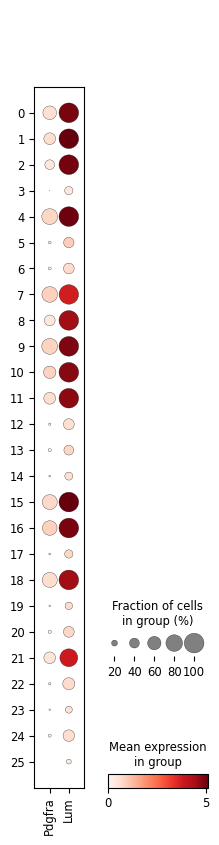

/tmp/ipykernel_1063/83433826.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ).join(mouse_sc.obs["leiden"]).groupby("leiden")[g].mean()



Mean Pdgfra expression by cluster:
leiden
16    0.910825
7     0.901230
10    0.868282
9     0.843007
4     0.806578
15    0.768188
18    0.694671
11    0.694163
1     0.679872
0     0.624047
21    0.480279
8     0.457614
2     0.416245
13    0.075603
20    0.072939
6     0.065281
5     0.062991
17    0.061668
14    0.044208
23    0.043806
12    0.042696
19    0.042224
22    0.041701
24    0.038422
3     0.006752
25    0.000000
Name: Pdgfra, dtype: float32


/tmp/ipykernel_1063/83433826.py:25: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ).join(mouse_sc.obs["leiden"]).groupby("leiden")[g].mean()



Mean Lum expression by cluster:
leiden
1     5.101898
15    5.086712
4     5.026409
2     4.950315
0     4.941461
16    4.904974
9     4.846331
10    4.765475
11    4.717052
18    4.499288
8     4.496858
21    3.799680
7     3.737005
5     0.965435
13    0.810411
17    0.795061
20    0.787047
19    0.728687
6     0.725050
22    0.716875
24    0.683490
12    0.672960
14    0.654275
23    0.631002
3     0.435196
25    0.385942
Name: Lum, dtype: float32


In [5]:
mouse_sc.layers["counts"] = mouse_sc.X.copy()
sc.pp.normalize_total(mouse_sc, target_sum=1e4)
sc.pp.log1p(mouse_sc)
mouse_sc.raw = mouse_sc

sc.pp.highly_variable_genes(mouse_sc, n_top_genes=2000)
mouse_sc_hvg = mouse_sc[:, mouse_sc.var["highly_variable"]].copy()

sc.pp.scale(mouse_sc_hvg, max_value=10)
sc.tl.pca(mouse_sc_hvg, n_comps=30)
sc.pp.neighbors(mouse_sc_hvg)
sc.tl.leiden(mouse_sc_hvg, resolution=1.0)

mouse_sc.obs["leiden"] = mouse_sc_hvg.obs["leiden"]

fib_markers = ["Pdgfra", "Lum"]
present = [g for g in fib_markers if g in mouse_sc.var_names]
print("Fibroblast markers found in data:", present)

sc.pl.dotplot(mouse_sc, present, groupby="leiden")

for g in present:
    expr_by_cluster = pd.DataFrame(
        mouse_sc[:, g].X.toarray().flatten(), index=mouse_sc.obs_names, columns=[g]
    ).join(mouse_sc.obs["leiden"]).groupby("leiden")[g].mean()
    print(f"\nMean {g} expression by cluster:")
    print(expr_by_cluster.sort_values(ascending=False))

out_dir = os.path.expanduser("~/FYP_Regeneration/data/mouse_sc/processed/")
mouse_sc.write(os.path.join(out_dir, "mouse_digit_clustered.h5ad"))

In [6]:
fibroblast_clusters = ['0','1','2','4','7','8','9','10','11','15','16','18','21']
mouse_sc.obs['is_fibroblast'] = mouse_sc.obs['leiden'].isin(fibroblast_clusters)

print(mouse_sc.obs['is_fibroblast'].value_counts())
print("\nFibroblasts by condition:")
print(pd.crosstab(mouse_sc.obs['condition'], mouse_sc.obs['is_fibroblast']))

mouse_fib = mouse_sc[mouse_sc.obs['is_fibroblast']].copy()
print(f"\nFibroblast subset: {mouse_fib.n_obs} cells")
print(mouse_fib.obs['regen_status'].value_counts())

is_fibroblast
True     24344
False    13441
Name: count, dtype: int64

Fibroblasts by condition:
is_fibroblast  False  True 
condition                  
11dpa           1901   5542
12dpa            983   2356
14dpa           1670   4200
17dpa           3864   4694
UA              5023   7552

Fibroblast subset: 24344 cells
regen_status
Regenerating    16792
Uninjured        7552
Name: count, dtype: int64


In [7]:
sc.tl.rank_genes_groups(
    mouse_fib, "regen_status",
    groups=["Regenerating"], reference="Uninjured",
    method="wilcoxon"
)

result = mouse_fib.uns["rank_genes_groups"]
de_df = pd.DataFrame({
    "gene": result["names"]["Regenerating"],
    "logfoldchanges": result["logfoldchanges"]["Regenerating"],
    "pvals_adj": result["pvals_adj"]["Regenerating"],
})
sig_df = de_df[(de_df["pvals_adj"] < 0.05) & (de_df["logfoldchanges"].abs() > 1.0)]

tables_dir = os.path.expanduser("~/FYP_Regeneration/results/tables/")
de_df.to_csv(os.path.join(tables_dir, "mouse_sc_fibroblast_regen_vs_uninjured_all.csv"), index=False)
sig_df.to_csv(os.path.join(tables_dir, "mouse_sc_fibroblast_regen_vs_uninjured_sig.csv"), index=False)

print(f"Significant genes: {len(sig_df)}")
print(sig_df.head(20))

# Pre-specified positive controls — written down before looking at results
positive_controls = ["Mest", "Msx1", "Msx2", "Sp6", "Sp8", "Fgf8", "Kazald1", "Kazald2"]
print("\nPositive controls in this test:")
print(de_df[de_df["gene"].isin(positive_controls)])

out_dir = os.path.expanduser("~/FYP_Regeneration/data/mouse_sc/processed/")
mouse_fib.write(os.path.join(out_dir, "mouse_fibroblast_only.h5ad"))

Significant genes: 991
        gene  logfoldchanges  pvals_adj
0     Tmsb10        1.662803        0.0
1    Col11a1        2.363699        0.0
2   Tnfrsf19        2.757439        0.0
3       Mest        5.962614        0.0
4      Csrp2        2.012847        0.0
6       Tpm1        1.777133        0.0
7      Fndc1        1.991186        0.0
8        Cpe        1.693400        0.0
10     Rpl38        1.210066        0.0
11     Thbs1        2.180234        0.0
12      Gas6        1.716526        0.0
15     Timp1        1.576838        0.0
16     Thbs2        1.494770        0.0
17     Rps28        1.351008        0.0
18   C1qtnf6        1.364860        0.0
19    Sec61g        1.308225        0.0
20   Col12a1        1.185868        0.0
22      Alpl        1.781776        0.0
23    Fkbp11        1.638661        0.0
24   S100a11        1.070777        0.0

Positive controls in this test:
          gene  logfoldchanges     pvals_adj
3         Mest        5.962614  0.000000e+00
4430      Msx1

In [8]:
import pandas as pd
import numpy as np
from scipy.stats import spearmanr

tables_dir = os.path.expanduser("~/FYP_Regeneration/results/tables/")

ax_all = pd.read_csv(os.path.join(tables_dir, "axolotl_regen_vs_uninjured_all.csv"))
ms_all = pd.read_csv(os.path.join(tables_dir, "mouse_sc_fibroblast_regen_vs_uninjured_all.csv"))

ax_all["gene_upper"] = ax_all["gene"].astype(str).str.upper()
ms_all["gene_upper"] = ms_all["gene"].astype(str).str.upper()

merged = pd.merge(
    ax_all[["gene_upper", "logfoldchanges", "pvals_adj"]].rename(
        columns={"logfoldchanges": "axolotl_lfc", "pvals_adj": "axolotl_padj"}),
    ms_all[["gene_upper", "logfoldchanges", "pvals_adj"]].rename(
        columns={"logfoldchanges": "mouse_lfc", "pvals_adj": "mouse_padj"}),
    on="gene_upper", how="inner"
)
merged = merged.replace([np.inf, -np.inf], np.nan).dropna(subset=["axolotl_lfc", "mouse_lfc"])
print(f"Shared genes tested in both species: {len(merged)}")

rho, p_parametric = spearmanr(merged["axolotl_lfc"], merged["mouse_lfc"])
print(f"\nObserved Spearman rho: {rho:.4f} (parametric p={p_parametric:.3g})")

# Permutation test — shuffle mouse fold-changes 10,000x, rebuild null distribution
np.random.seed(42)
n_perm = 10000
null_rhos = np.zeros(n_perm)
mouse_vals = merged["mouse_lfc"].values.copy()
for i in range(n_perm):
    shuffled = np.random.permutation(mouse_vals)
    null_rhos[i], _ = spearmanr(merged["axolotl_lfc"].values, shuffled)

p_empirical = (np.sum(np.abs(null_rhos) >= np.abs(rho)) + 1) / (n_perm + 1)
print(f"Permutation p-value (10,000 shuffles): {p_empirical:.4g}")
print(f"Null distribution: mean={null_rhos.mean():.4f}, std={null_rhos.std():.4f}")

merged.to_csv(os.path.join(tables_dir, "axolotl_mouse_fc_correlation_v3.csv"), index=False)

# Where do the positive controls sit?
controls_upper = ["MEST", "MSX1", "MSX2", "SP6", "SP8", "FGF8", "KAZALD1", "KAZALD2"]
print("\nPositive controls in the merged correlation set:")
print(merged[merged["gene_upper"].isin(controls_upper)])

# Concordant direction check (both up or both down) as a simple sanity measure
concordant = ((merged["axolotl_lfc"] > 0) & (merged["mouse_lfc"] > 0)) | \
             ((merged["axolotl_lfc"] < 0) & (merged["mouse_lfc"] < 0))
print(f"\nGenes changing in the same direction in both species: "
      f"{concordant.sum()} / {len(merged)} ({100*concordant.mean():.1f}%)")

Shared genes tested in both species: 11544

Observed Spearman rho: 0.0845 (parametric p=9.83e-20)
Permutation p-value (10,000 shuffles): 9.999e-05
Null distribution: mean=-0.0001, std=0.0093

Positive controls in the merged correlation set:
      gene_upper  axolotl_lfc  axolotl_padj  mouse_lfc    mouse_padj
1425        MSX2     2.502798      0.020234  -0.124353  1.111324e-06
2933        FGF8     2.938316      0.299882  18.806390  1.000000e+00
3323        MSX1    26.699896      0.425260   0.292499  2.614512e-20
7175         SP8     1.654038      1.000000  -2.094723  1.000000e+00
7511        MEST    -0.355557      1.000000   5.962614  0.000000e+00
7741         SP6    21.755650      1.000000   0.480141  1.000000e+00
10651    KAZALD1    -0.778026      0.554494  -0.294560  1.744519e-03

Genes changing in the same direction in both species: 7124 / 11544 (61.7%)


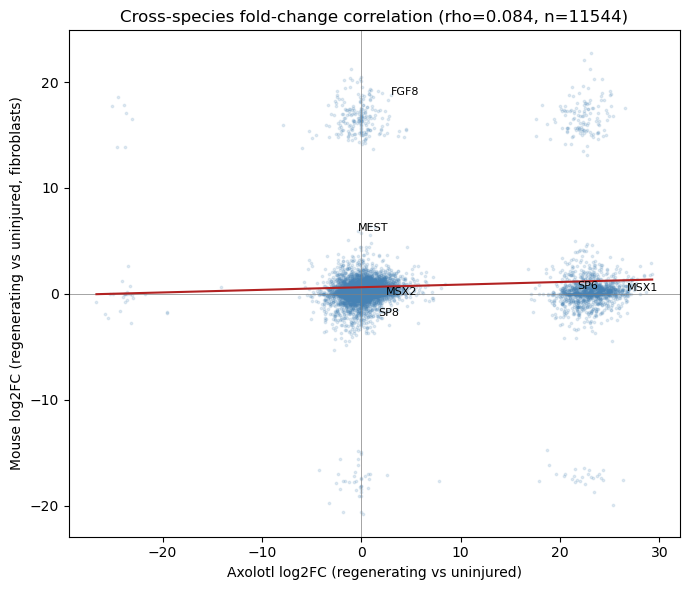

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(merged["axolotl_lfc"], merged["mouse_lfc"], s=3, alpha=0.15, color="steelblue")
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)

z = np.polyfit(merged["axolotl_lfc"], merged["mouse_lfc"], 1)
xs = np.linspace(merged["axolotl_lfc"].min(), merged["axolotl_lfc"].max(), 100)
ax.plot(xs, np.polyval(z, xs), color="firebrick", lw=1.5)

for _, row in merged[merged["gene_upper"].isin(
        ["MEST","MSX1","MSX2","SP6","SP8","FGF8"])].iterrows():
    ax.annotate(row["gene_upper"], (row["axolotl_lfc"], row["mouse_lfc"]), fontsize=8)

ax.set_xlabel("Axolotl log2FC (regenerating vs uninjured)")
ax.set_ylabel("Mouse log2FC (regenerating vs uninjured, fibroblasts)")
ax.set_title(f"Cross-species fold-change correlation (rho={rho:.3f}, n={len(merged)})")
plt.tight_layout()

fig_dir = os.path.expanduser("~/FYP_Regeneration/results/figures/cross_species/")
os.makedirs(fig_dir, exist_ok=True)
plt.savefig(os.path.join(fig_dir, "axolotl_mouse_fc_correlation_v3.png"), dpi=300)
plt.show()